In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Racine du projet : on remonte jusqu'au dossier qui contient data/processed/index.csv
ROOT = Path.cwd()
while not (ROOT / "data/processed/index.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / "data/processed/index.csv").exists(), "index.csv introuvable : lance d'abord src/data/make_index.py"

RAW = ROOT / "data/raw/SDNET2018_images"
FIG = ROOT / "reports/figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED = 42
rng = np.random.default_rng(SEED)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"     # sain, fissure, 3e série
SURF = {"D": "Pont (D)", "P": "Chaussée (P)", "W": "Mur (W)"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e7e6e2", "axes.axisbelow": True})
print("Racine du projet :", ROOT)

Racine du projet : c:\Users\ahmed\projet-dl-mlops


In [2]:
df = pd.read_csv(ROOT / "data/processed/index.csv")
print("Dimensions :", df.shape)
print("Valeurs manquantes par colonne :")
print(df.isna().sum().to_string())
df.head(8)

Dimensions : (56092, 5)
Valeurs manquantes par colonne :
path       0
label      0
surface    0
photo      0
split      0


,path,label,surface,photo,split
0,D/CD/7001-115.jpg,1,D,D_7001,val
1,D/CD/7001-139.jpg,1,D,D_7001,val
2,D/CD/7001-151.jpg,1,D,D_7001,val
3,D/CD/7001-157.jpg,1,D,D_7001,val
4,D/CD/7001-169.jpg,1,D,D_7001,val
5,D/CD/7001-17.jpg,1,D,D_7001,val
6,D/CD/7001-173.jpg,1,D,D_7001,val
7,D/CD/7001-178.jpg,1,D,D_7001,val


label,sans fissure,fissure,total,% fissure
surface,,,,
D,11595,2025,13620,14.9
P,21726,2608,24334,10.7
W,14287,3851,18138,21.2


Total : 56092 patchs, dont 8484 avec fissure (15.1 %).
Un modèle qui répond toujours 'sain' aurait 84.9 % d'accuracy sans détecter aucune fissure.


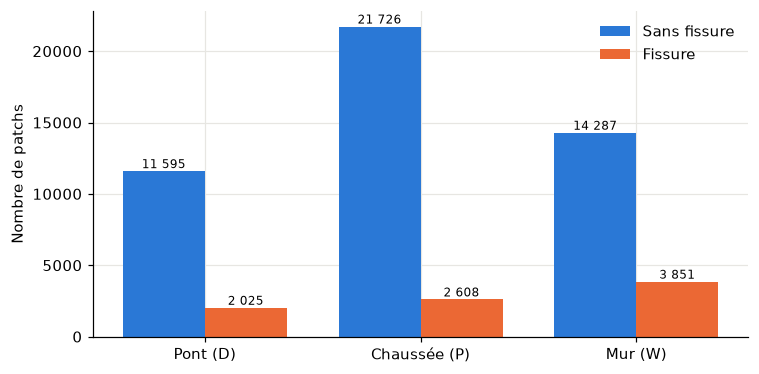

In [3]:
cnt = df.groupby(["surface", "label"]).size().unstack(fill_value=0).rename(columns={0: "sans fissure", 1: "fissure"})
cnt["total"] = cnt.sum(axis=1)
cnt["% fissure"] = (100 * cnt["fissure"] / cnt["total"]).round(1)
display(cnt)

tot = len(df); n_fis = int(df.label.sum())
print(f"Total : {tot} patchs, dont {n_fis} avec fissure ({100*n_fis/tot:.1f} %).")
print(f"Un modèle qui répond toujours 'sain' aurait {100*(tot-n_fis)/tot:.1f} % d'accuracy sans détecter aucune fissure.")

fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(cnt)); w = 0.38
ax.bar(x - w/2, cnt["sans fissure"], w, color=BLUE, label="Sans fissure")
ax.bar(x + w/2, cnt["fissure"], w, color=ORANGE, label="Fissure")
for i, (s, f) in enumerate(zip(cnt["sans fissure"], cnt["fissure"])):
    ax.text(i - w/2, s, f"{s:,}".replace(",", " "), ha="center", va="bottom", fontsize=8)
    ax.text(i + w/2, f, f"{f:,}".replace(",", " "), ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels([SURF[s] for s in cnt.index]); ax.set_ylabel("Nombre de patchs")
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(FIG / "01_classes_par_surface.png", dpi=200); plt.show()

Photos par surface : {'D': 54, 'P': 104, 'W': 72} | total : 230


surface              D      P      W
patchs    count   54.0  104.0   72.0
          mean   252.2  234.0  251.9
          std      1.2    0.2    0.7
          min    252.0  232.0  246.0
          25%    252.0  234.0  252.0
          50%    252.0  234.0  252.0
          75%    252.0  234.0  252.0
          max    260.0  234.0  253.0
% fissure count   54.0  104.0   72.0
          mean    14.9   10.7   21.2
          std      7.8    5.0   14.1
          min      1.2    0.0    6.7
          25%      9.1    8.5    9.5
          50%     13.5    9.8   15.9
          75%     19.4   12.0   29.9
          max     32.9   26.1   60.3

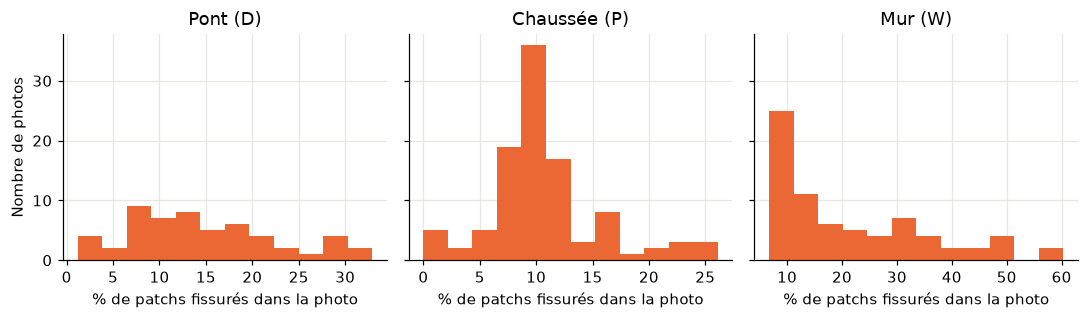

In [4]:
ph = df.groupby(["surface", "photo"]).agg(patchs=("path", "size"), fissures=("label", "sum")).reset_index()
ph["% fissure"] = (100 * ph["fissures"] / ph["patchs"]).round(1)
print("Photos par surface :", ph.groupby("surface").size().to_dict(), "| total :", len(ph))
display(ph.groupby("surface")[["patchs", "% fissure"]].describe().round(1).T)

fig, axes = plt.subplots(1, 3, figsize=(10, 3), sharey=True)
for ax, s in zip(axes, SURF):
    ax.hist(ph.loc[ph.surface == s, "% fissure"], bins=12, color=ORANGE)
    ax.set_title(SURF[s]); ax.set_xlabel("% de patchs fissurés dans la photo")
axes[0].set_ylabel("Nombre de photos")
fig.tight_layout(); fig.savefig(FIG / "02_fissures_par_photo.png", dpi=200); plt.show()

,patchs,fissures,photos,% fissure
split,,,,
train,39260,5783,161,14.7
val,8534,1400,35,16.4
test,8298,1301,34,15.7


Aucune photo n'est présente dans deux splits : OK


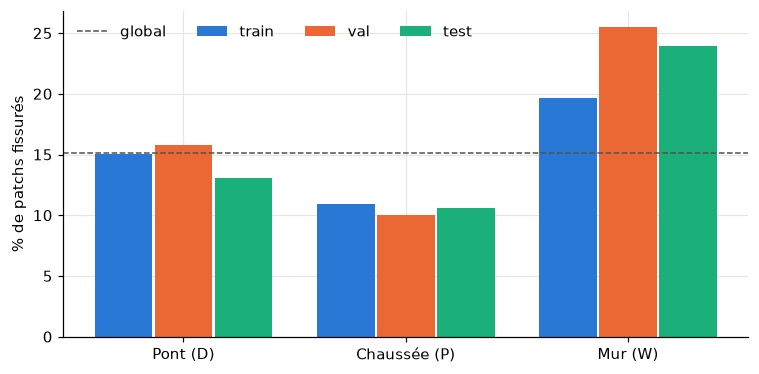

In [5]:
sp = df.groupby("split").agg(patchs=("path", "size"), fissures=("label", "sum"), photos=("photo", "nunique"))
sp["% fissure"] = (100 * sp["fissures"] / sp["patchs"]).round(1)
display(sp.reindex(["train", "val", "test"]))

# Contrôle de fuite : une photo ne doit apparaître que dans un seul split
n_split = df.groupby("photo")["split"].nunique()
assert n_split.max() == 1, "FUITE : une photo est dans plusieurs splits"
print("Aucune photo n'est présente dans deux splits : OK")

rate = (df.groupby(["surface", "split"])["label"].mean() * 100).unstack().reindex(columns=["train", "val", "test"])
fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(3); w = 0.26
for j, (c, col) in enumerate(zip(["train", "val", "test"], [BLUE, ORANGE, AQUA])):
    ax.bar(x + (j - 1) * (w + 0.01), rate[c].reindex(list(SURF)), w, color=col, label=c)
ax.axhline(100 * df.label.mean(), color="#52514e", lw=1, ls="--", label="global")
ax.set_xticks(x); ax.set_xticklabels([SURF[s] for s in SURF]); ax.set_ylabel("% de patchs fissurés")
ax.legend(frameon=False, ncol=4); fig.tight_layout(); fig.savefig(FIG / "03_taux_par_split.png", dpi=200); plt.show()

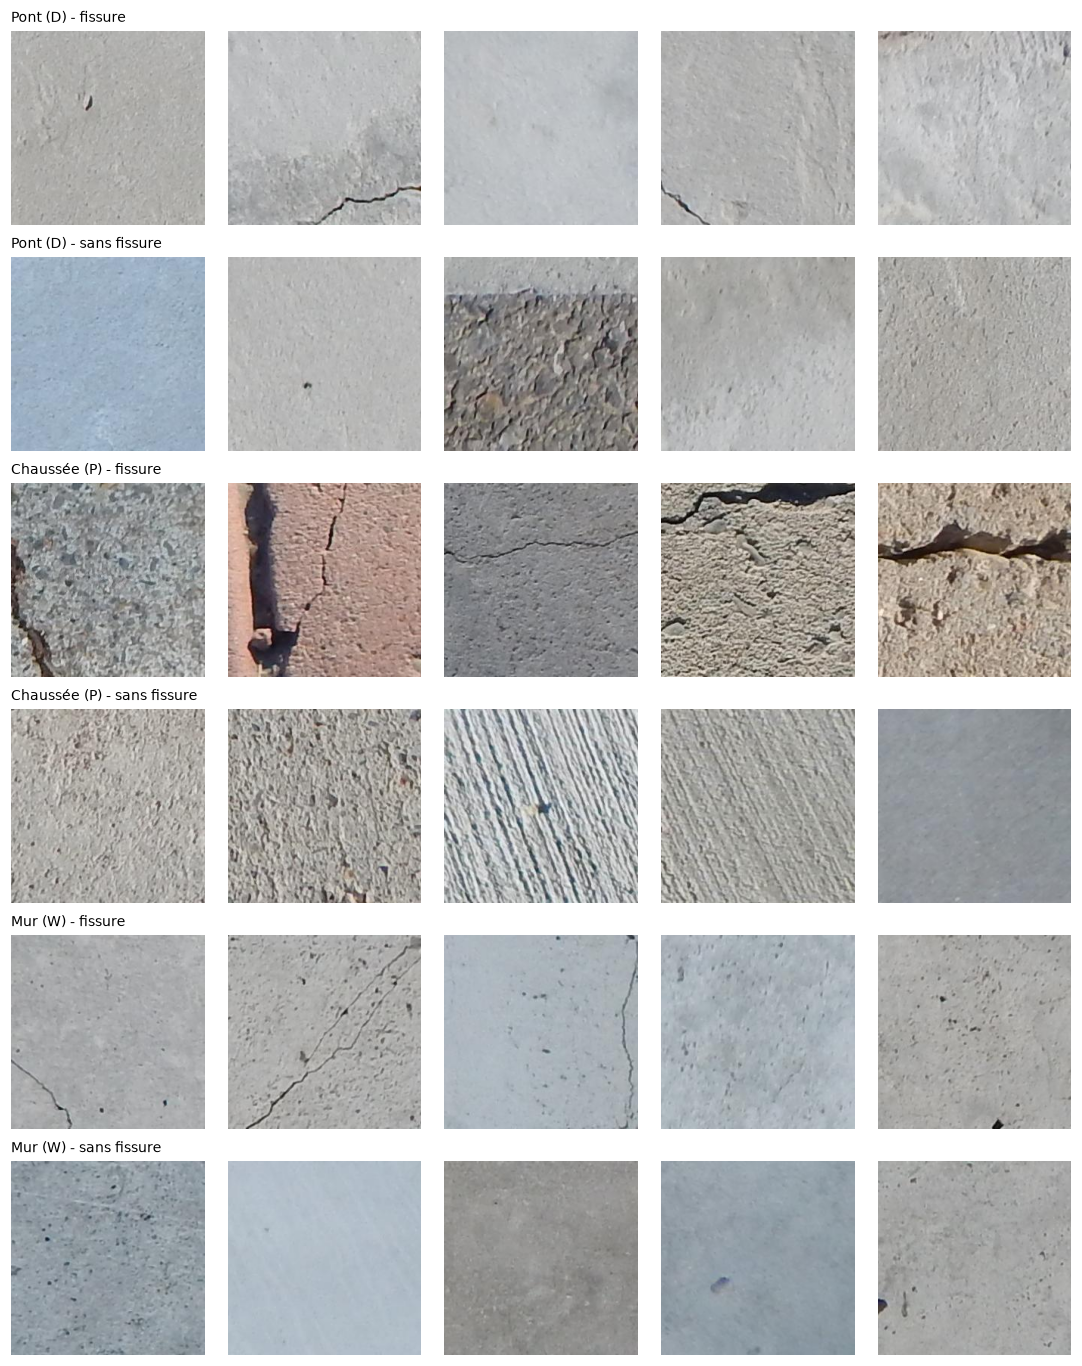

In [6]:
tr = df[df.split == "train"]
fig, axes = plt.subplots(6, 5, figsize=(10, 12.5))
r = 0
for s in SURF:
    for lab, txt in ((1, "fissure"), (0, "sans fissure")):
        sub = tr[(tr.surface == s) & (tr.label == lab)]
        pick = sub.iloc[rng.choice(len(sub), min(5, len(sub)), replace=False)]
        for c in range(5):
            ax = axes[r, c]; ax.axis("off")
            if c < len(pick):
                ax.imshow(Image.open(RAW / pick.iloc[c]["path"]))
            if c == 0:
                ax.set_title(f"{SURF[s]} - {txt}", fontsize=9, loc="left")
        r += 1
fig.tight_layout(); fig.savefig(FIG / "04_exemples.png", dpi=150); plt.show()

,même photo,photos différentes,rapport
surface,,,
Pont (D),14.780000,15.42,1.04
Chaussée (P),24.620001,29.42,1.19
Mur (W),11.300000,14.82,1.31


Différence moyenne de pixels (0 à 255). Un rapport supérieur à 1 signifie que les patchs d'une même photo se ressemblent plus.


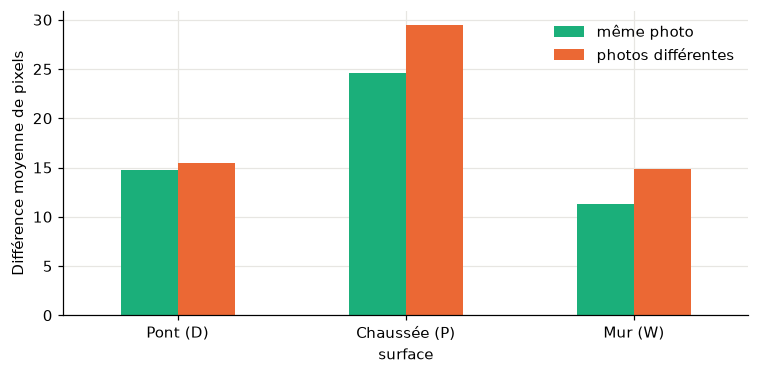

In [7]:
def thumb(path):
    return np.asarray(Image.open(RAW / path).convert("L").resize((32, 32)), dtype=np.float32)

rows = []
for s in SURF:
    sub = df[df.surface == s]
    photos = [p for p, g in sub.groupby("photo") if len(g) >= 10]
    photos = list(rng.choice(photos, size=min(12, len(photos)), replace=False))
    th = {p: [thumb(x) for x in sub[sub.photo == p].sample(min(15, (sub.photo == p).sum()), random_state=SEED)["path"]]
          for p in photos}
    same, diff = [], []
    for p in photos:
        t = th[p]
        for _ in range(60):
            i, j = rng.choice(len(t), 2, replace=False); same.append(np.abs(t[i] - t[j]).mean())
        for _ in range(60):
            q = rng.choice([x for x in photos if x != p]) if len(photos) > 1 else p
            diff.append(np.abs(t[rng.integers(len(t))] - th[q][rng.integers(len(th[q]))]).mean())
    rows.append({"surface": SURF[s], "même photo": np.mean(same), "photos différentes": np.mean(diff),
                 "rapport": np.mean(diff) / np.mean(same)})
res = pd.DataFrame(rows).set_index("surface").round(2)
display(res)
print("Différence moyenne de pixels (0 à 255). Un rapport supérieur à 1 signifie que les patchs d'une même photo se ressemblent plus.")

res[["même photo", "photos différentes"]].plot.bar(figsize=(7, 3.5), color=[AQUA, ORANGE], rot=0)
plt.ylabel("Différence moyenne de pixels"); plt.legend(frameon=False); plt.tight_layout()
plt.savefig(FIG / "05_similarite_meme_photo.png", dpi=200); plt.show()

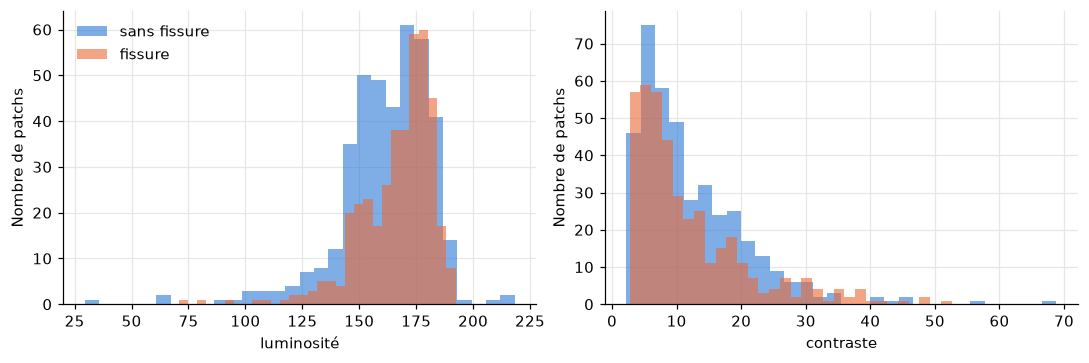

luminosité            contraste     
            mean        std      mean  std
label                                     
0          161.9  20.799999      12.3  8.7
1          166.5  16.600000      11.9  9.0

In [8]:
n = min(400, int(df.label.sum()))
samp = pd.concat([df[df.label == l].sample(n, random_state=SEED) for l in (0, 1)])
stats = []
for r_ in samp.itertuples(index=False):
    a = np.asarray(Image.open(RAW / r_.path).convert("L").resize((64, 64)), dtype=np.float32)
    stats.append((r_.label, a.mean(), a.std()))
st = pd.DataFrame(stats, columns=["label", "luminosité", "contraste"])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, col in zip(axes, ["luminosité", "contraste"]):
    for l, c, name in ((0, BLUE, "sans fissure"), (1, ORANGE, "fissure")):
        ax.hist(st.loc[st.label == l, col], bins=30, alpha=0.6, color=c, label=name)
    ax.set_xlabel(col); ax.set_ylabel("Nombre de patchs")
axes[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "06_luminosite_contraste.png", dpi=200); plt.show()
display(st.groupby("label")[["luminosité", "contraste"]].agg(["mean", "std"]).round(1))